In [14]:
import torch
import numpy as np

In [15]:
VOCAB = {"A": 1, "C": 2, "G": 3, "U": 4, "EMPTY": 0}

In [16]:
def encode(seq):
    """Convert an RNA sequence into a list of integer token ids.
    Parameters:
    -----------
        seq (str): RNA sequence made of the letters A, C, G and U.
        
    Returns:
    --------
        list[int]: One token id per nucleotide, in the same order as `seq`.
    """
    return [VOCAB[nuc] for nuc in seq]

In [17]:
def fill_empty(list_of_sequences):
    number_of_sequence = len(list_of_sequences)
    seq_length_max = 0
    for sequence in list_of_sequences:
        length = len(sequence)
        if length > seq_length_max:
            seq_length_max = length
            
    tokens = np.full((number_of_sequence, seq_length_max), VOCAB["EMPTY"])
    
    for line, seq in enumerate(list_of_sequences):
        tokens[line,0 :len(seq)] = seq
    mask = tokens != VOCAB["EMPTY"]
    return tokens, mask

In [18]:
class NucleotideEmbedding(nn.Module):
    def __init__(self, dim=192):
        super().__init__()
        self.emb = nn.Embedding(len(VOCAB), dim)

    def forward(self, tokens):
        return self.emb(tokens)

In [19]:
tokens = torch.tensor([encode("GGAAUC")])
print(tokens)

emb = NucleotideEmbedding(dim=192)
out = emb(tokens)
print(out.shape)
batch = [encode("GGAAUC"), encode("GGA")]
tokens, mask = fill_empty(batch)
print(tokens)
print(mask)
print(emb(tokens).shape)

tensor([[3, 3, 1, 1, 4, 2]])
torch.Size([1, 6, 192])
tensor([[3, 3, 1, 1, 4, 2],
        [3, 3, 1, 0, 0, 0]])
tensor([[ True,  True,  True,  True,  True,  True],
        [ True,  True,  True, False, False, False]])
torch.Size([2, 6, 192])


In [30]:
import numpy as np

def lire_bpp(chemin, L):
    grille = np.zeros((L, L))

    with open(chemin) as f:
        for ligne in f:
            if not ligne.strip():
                continue

            i, j, proba = ligne.split()
            i, j = int(i) - 1, int(j) - 1

            grille[i, j] = float(proba)
            grille[j, i] = float(proba)

    return grille


In [31]:
seq = "A" *100 + "C" * 70
grille = lire_bpp("00257e85caac.txt", len(seq))

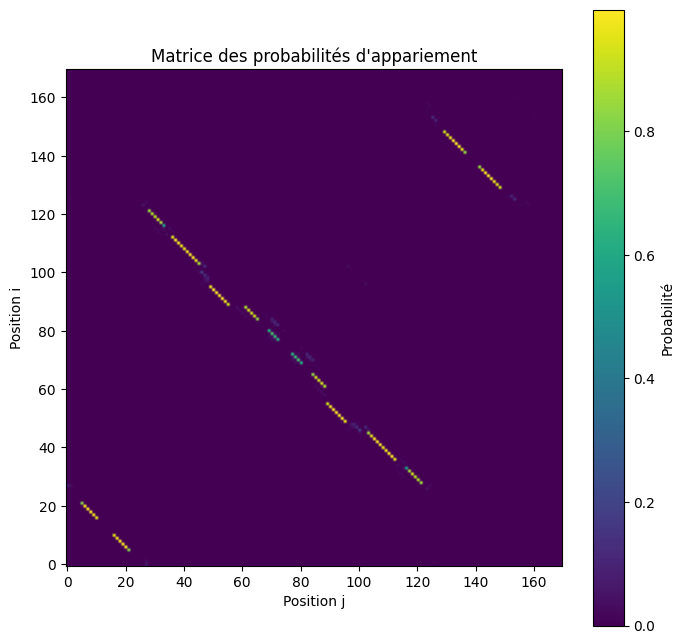

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.imshow(grille, cmap="viridis", origin="lower")
plt.colorbar(label="Probabilité")
plt.xlabel("Position j")
plt.ylabel("Position i")
plt.title("Matrice des probabilités d'appariement")
plt.show()

In [ ]:
class TestModel(nn.Module): 
    def __init__(self, dim=16, n_outputs=1):
        super().__init__()
        self.embedding = NucleotideEmbedding(dim)
        self.conv = nn.Conv1d(dim, dim, kernel_size=3, padding=1)
        self.head = nn.Linear(dim, n_outputs)
 
    def forward(self, tokens):
        x = self.embedding(tokens)
        x = x.transpose(1, 2) 
        x = torch.relu(self.conv(x)) 
        x = x.transpose(1, 2)  
        return self.head(x).squeeze(-1) 

In [ ]:
model = TestModel(dim=16)
tokens, mask = fill_empty([encode("GGAAUC"), encode("GGA")])
pred = model(tokens)
print(pred.shape)  